
# Iris Flower Classification Using Machine Learning

## 1. Introduction

The Iris flower classification problem is a classic supervised machine learning task. The objective is to develop a classification model that predicts the species of an iris flower using four numerical measurements.

This project uses the Iris dataset available through the Scikit-learn library. The dataset contains measurements from three iris species: *Iris setosa*, *Iris versicolor*, and *Iris virginica*.

### Project Objectives

The main objectives of this project are to:

1. Load and inspect the Iris dataset.
2. Perform exploratory data analysis (EDA) to understand the structure and characteristics of the data.
3. Visualize relationships between the input features and flower species.
4. Prepare the data for machine learning.
5. Train and compare multiple classification algorithms.
6. Evaluate model performance using accuracy, confusion matrices, precision, recall, and F1-score.
7. Identify the best-performing model based on evaluation results.

### Problem Statement

Given the sepal length, sepal width, petal length, and petal width of an iris flower, can a machine learning model accurately predict its species?

### Machine Learning Approach

This is a **supervised multiclass classification** problem. The four flower measurements are the input features, while the flower species is the target variable.

The dataset is divided into training and testing subsets. Classification models are trained on the training data and evaluated on the unseen testing data to estimate their predictive performance.


In [1]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset and machine learning utilities
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the built-in Iris dataset
iris = load_iris()

# Create a DataFrame containing the four input features
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the numerical target and human-readable species name
df["target"] = iris.target
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



## 2. Dataset Overview

Before building a machine learning model, it is important to understand the structure of the dataset. We will inspect its dimensions, column names, data types, and sample records.

This initial inspection helps identify the available features, the target variable, and any potential data-quality issues that need to be addressed before training.


In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Display the number of records for each species
print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 6)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64



## 3. Data Quality Assessment

Data quality assessment is an important step before model development. Missing values, duplicate records, and incorrect data types can affect the reliability of an analysis.

In this section, we will examine missing values in each column, check for duplicate observations, and verify that the dataset uses appropriate data types.

Because the Iris dataset is a clean, built-in dataset, extensive data cleaning may not be necessary. However, these checks are included to demonstrate a systematic data science workflow.


In [4]:
# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check the total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Inspect column data types
print("\nColumn data types:")
print(df.dtypes)

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Total missing values: 0

Number of duplicate rows: 1

Column data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object



## 4. Descriptive Statistical Analysis

Descriptive statistics provide an overview of the numerical features in the dataset. We will calculate the count, mean, standard deviation, minimum, maximum, and quartiles for each measurement.

These statistics help us understand the scale and variability of the features and identify possible differences in their distributions. We will also examine the measurements separately for each species to understand which features may be useful for classification.


In [5]:
# Summary statistics for the numerical columns
df[iris.feature_names].describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [6]:
# Calculate feature statistics separately for each species
df.groupby("species")[iris.feature_names].mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03



## 5. Target Variable Distribution

The target variable represents the species that the model will predict. Understanding its distribution is important because a strongly imbalanced dataset can make accuracy misleading.

We will visualize the number of observations belonging to each species to determine whether the dataset is balanced.


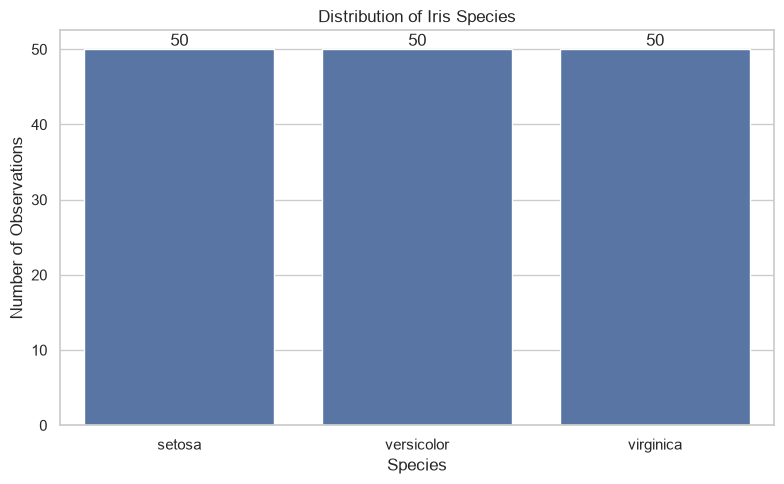

In [7]:
# Count observations for each species
species_counts = df["species"].value_counts().reindex(iris.target_names)

# Create a bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=species_counts.index,
    y=species_counts.values
)

ax.bar_label(ax.containers[0])
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()


### Interpretation

The Iris dataset contains three target classes: Setosa, Versicolor, and Virginica. Each class contains 50 observations, giving the dataset an equal class distribution.

This balanced distribution is useful for model evaluation because no species is disproportionately represented in the dataset. We will also use stratified sampling during the train/test split to preserve the class proportions in both subsets.



## 6. Distribution of Numerical Features

The four numerical features may have different ranges, spreads, and distribution patterns. Visualizing their distributions helps us identify differences in scale and potential overlap between measurements.

We will use histograms with density curves to examine the overall distribution of each feature. These plots will also help us understand whether standardization may be useful for algorithms that depend on feature scales or distances.


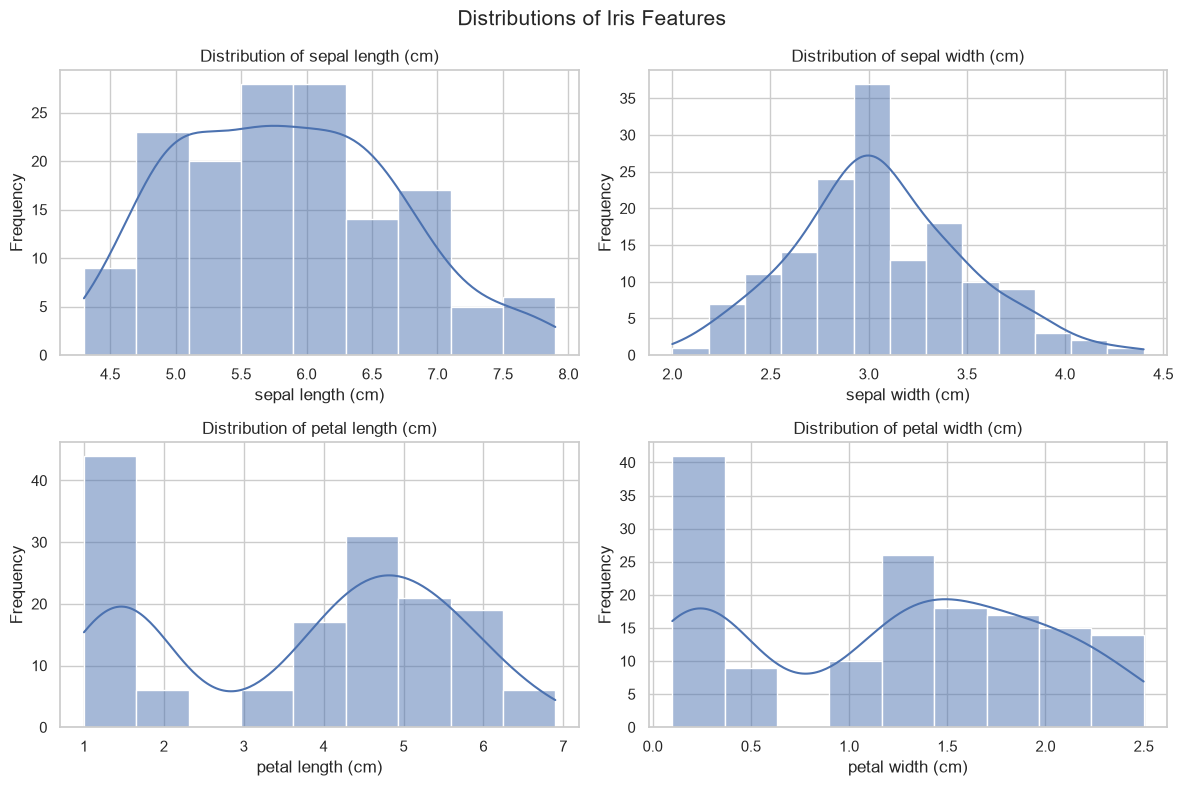

In [8]:
# Plot the distribution of each numerical feature
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, iris.feature_names):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.suptitle("Distributions of Iris Features", fontsize=15)
plt.tight_layout()
plt.show()


## 7. Feature Relationships and Species Separation

The usefulness of a classification model depends partly on how well the input features distinguish between target classes.

We will use a pairplot to examine relationships between every pair of numerical features. Points are colored by species, allowing us to observe whether the classes form distinct groups or overlap.

We will then use box plots to compare the distribution of each measurement across the three species. These visualizations will support our later discussion of feature selection and model performance.


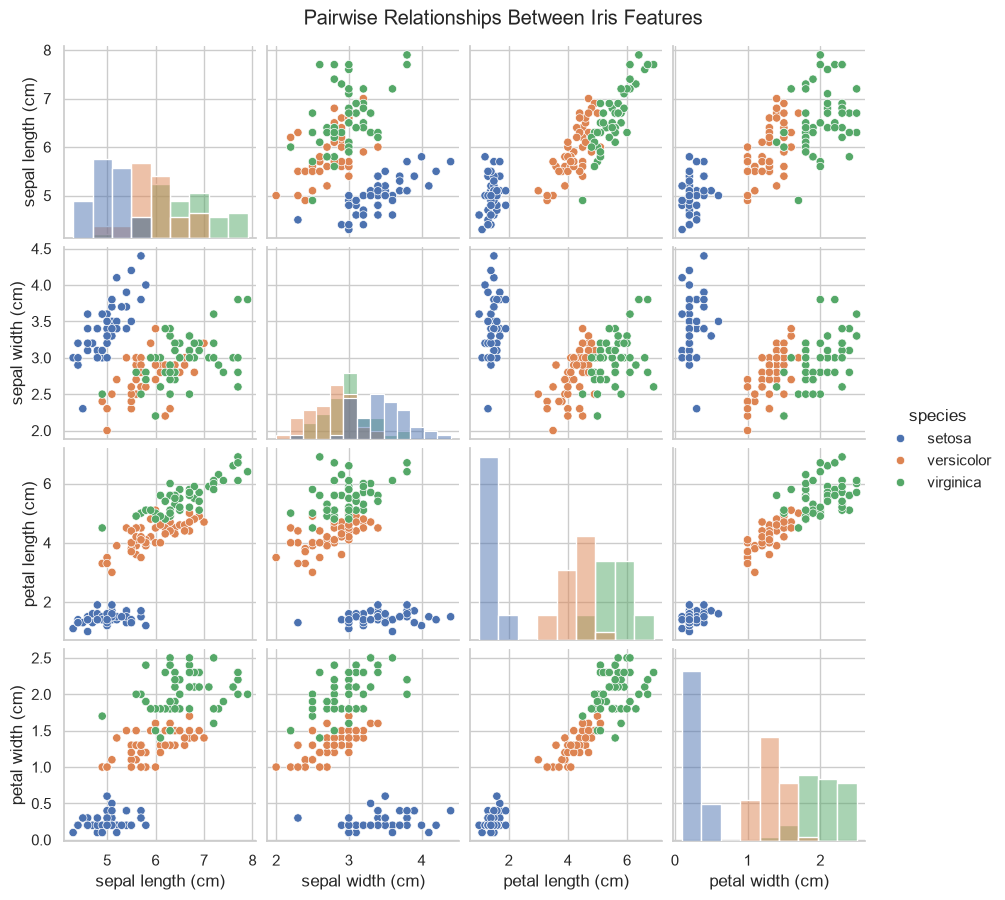

In [9]:
# Visualize pairwise relationships between features
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species",
    diag_kind="hist",
    height=2.2
)

plt.suptitle("Pairwise Relationships Between Iris Features", y=1.02)
plt.show()

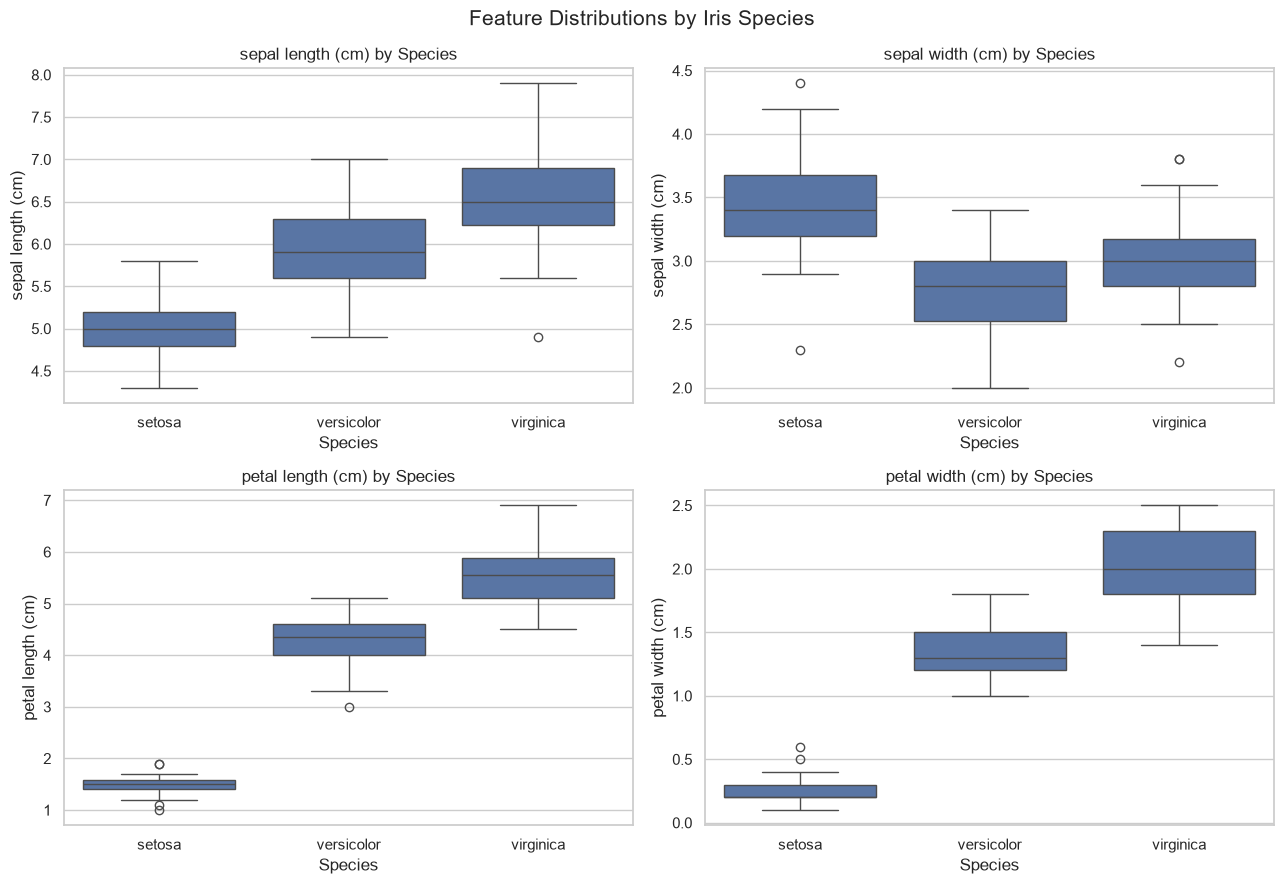

In [10]:
# Compare each feature across the three species
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, feature in zip(axes, iris.feature_names):
    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature)

plt.suptitle("Feature Distributions by Iris Species", fontsize=15)
plt.tight_layout()
plt.show()


### Interpretation of Feature Relationships

Examine the pairplot and box plots to identify which measurements show the clearest separation between species.

Petal length and petal width are generally expected to provide strong discriminatory information, particularly for distinguishing Setosa from the other species. Sepal measurements may show greater overlap between classes.

These observations suggest that petal measurements may be particularly informative for classification. However, visual separation alone does not establish which features are most useful in a predictive model. We will evaluate model performance on held-out test data before drawing final conclusions.



## 8. Feature Selection and Rationale

Feature selection involves identifying input variables that provide useful information for predicting the target variable. It can improve interpretability, reduce unnecessary complexity, and sometimes improve generalization.

The Iris dataset contains four numerical features:

- Sepal length (cm)
- Sepal width (cm)
- Petal length (cm)
- Petal width (cm)

Based on the exploratory visualizations, petal length and petal width appear particularly informative because they generally show clearer separation between species. Sepal measurements may provide additional information but can exhibit greater overlap.

For this project, we will initially retain all four features rather than remove any based solely on visual inspection. This allows us to establish a baseline using the complete feature set and compare several classification algorithms under the same conditions.

The numerical features will be standardized for Logistic Regression and K-Nearest Neighbors, which can be sensitive to feature scales. Random Forest will be trained without standardization because tree-based models generally do not require features to be on the same scale.

We will use a held-out test set to compare the models and determine which approach performs best.


In [11]:
# Define the input features and target variable
X = df[iris.feature_names].copy()
y = df["target"].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget classes:")
print(dict(enumerate(iris.target_names)))

Feature matrix shape: (150, 4)
Target vector shape: (150,)

Input features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
{0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}



## 9. Train-Test Split

To evaluate how well the models generalize to unseen observations, we will divide the dataset into training and testing subsets.

We will allocate 80% of the observations to training and 20% to testing. The models will learn patterns from the training subset, while the testing subset will be reserved for final evaluation.

We will use stratified sampling to preserve the relative proportion of each species in both subsets. A fixed random state ensures that the split is reproducible.

The test data will not be used to fit the models or their preprocessing steps.


In [12]:
# Split the dataset into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining set class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting set class distribution:")
print(y_test.value_counts().sort_index())

Training feature shape: (120, 4)
Testing feature shape: (30, 4)

Training set class distribution:
target
0    40
1    40
2    40
Name: count, dtype: int64

Testing set class distribution:
target
0    10
1    10
2    10
Name: count, dtype: int64



## 10. Model Training

We will train three classification algorithms: Logistic Regression, K-Nearest Neighbors, and Random Forest.

To ensure a fair comparison, all models will use the same training and testing split. StandardScaler will be included in the pipelines for Logistic Regression and KNN so that scaling parameters are learned exclusively from the training data. Random Forest will use the original feature values.

Using pipelines helps prevent data leakage during preprocessing and keeps the training workflow reproducible.


In [13]:
# Define the classification models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

# Train each model using only the training data
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
K-Nearest Neighbors trained successfully.
Random Forest trained successfully.



## 11. Model Evaluation

We will evaluate each trained model on the held-out test set using multiple performance metrics.

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** The proportion of predictions for a class that are correct.
- **Recall:** The proportion of actual observations of a class that the model correctly identifies.
- **F1-score:** The harmonic mean of precision and recall.
- **Confusion matrix:** A table showing correct and incorrect predictions for each species.

Because this is a multiclass classification task, we will report macro-averaged precision, recall, and F1-score. Macro averaging calculates each class's metric separately and then gives all three classes equal weight.

Accuracy alone may not reveal which species a model misclassifies. The additional metrics and confusion matrices provide a more complete assessment.


In [14]:
# Evaluate each model on the held-out test set
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": classification_report(
            y_test, y_pred, output_dict=True, zero_division=0
        )["macro avg"]["precision"],
        "Recall (Macro)": classification_report(
            y_test, y_pred, output_dict=True, zero_division=0
        )["macro avg"]["recall"],
        "F1-Score (Macro)": classification_report(
            y_test, y_pred, output_dict=True, zero_division=0
        )["macro avg"]["f1-score"]
    })

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,K-Nearest Neighbors,0.9333,0.9444,0.9333,0.9327
2,Random Forest,0.9000,0.9024,0.9000,0.8997


In [15]:
# Display the detailed classification report for each model
for name, y_pred in predictions.items():
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1, 2],
            target_names=iris.target_names,
            digits=4,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30


K-Nearest Neighbors
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.8333    1.0000    0.9091        10
   virginica     1.0000    0.8000    0.8889        10

    accuracy                         0.9333        30
   macro avg     0.9444    0.9333    0.9327        30
weighted avg     0.9444    0.9333    0.9327        30


Random Forest
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.8182    0.9000    0.8571        10
   virginica     0

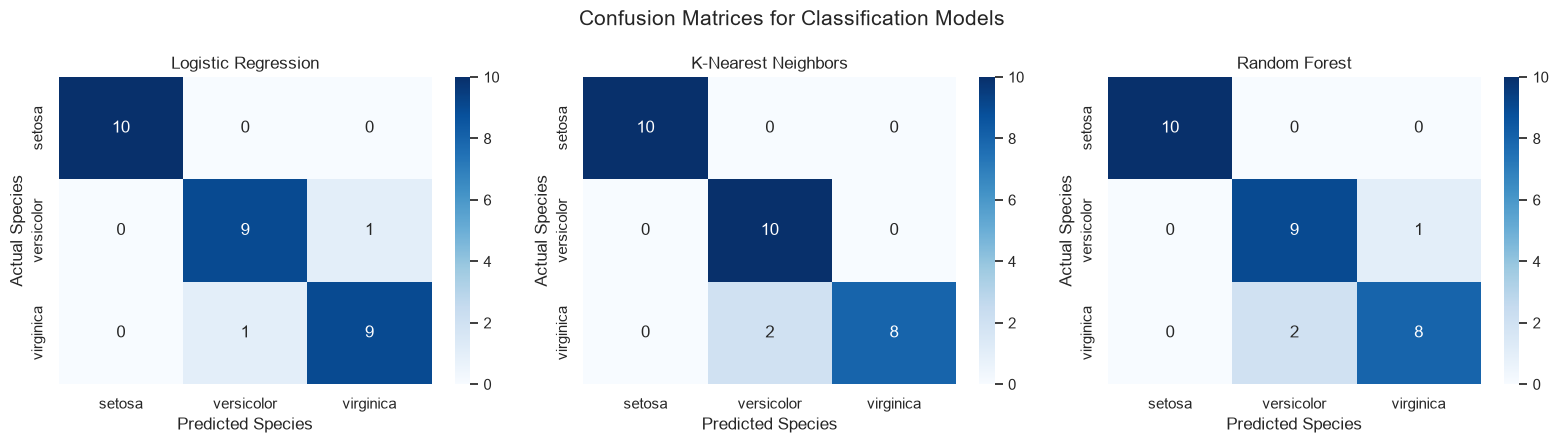

In [16]:
# Visualize the confusion matrix for each classifier
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.suptitle("Confusion Matrices for Classification Models", fontsize=15)
plt.tight_layout()
plt.show()

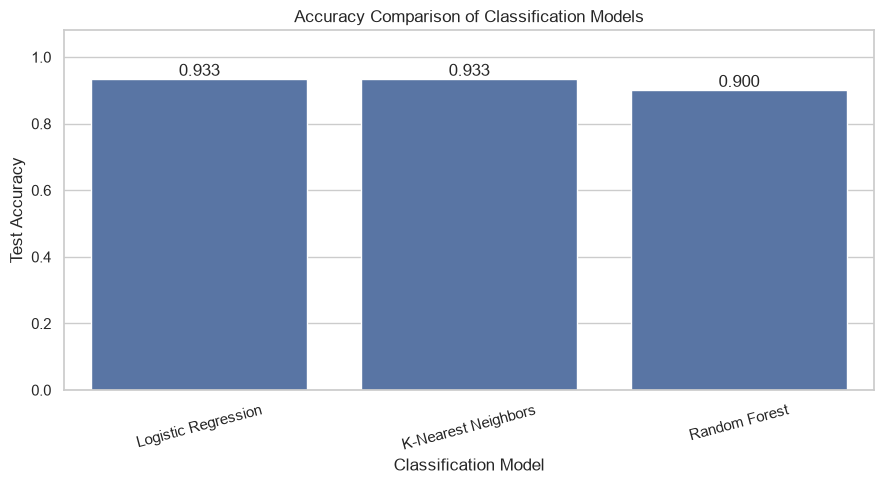

In [17]:
# Plot model accuracy for an easier comparison
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

ax.bar_label(ax.containers[0], fmt="%.3f")
plt.ylim(0, 1.08)
plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 12. Comparative Analysis of Classification Models

The three classification algorithms were evaluated using the same held-out test dataset containing 30 observations, with 10 observations from each species.

### Logistic Regression

Logistic Regression achieved an accuracy of 93.33%, with macro-averaged precision, recall, and F1-score of 93.33%. It correctly classified all Setosa observations, while its precision and recall for Versicolor and Virginica were both 90.00%.

These results indicate that Logistic Regression provides strong and relatively balanced classification performance on this test set.

### K-Nearest Neighbors

K-Nearest Neighbors also achieved an accuracy of 93.33%. It recorded the highest macro precision of 94.44%, with macro recall of 93.33% and macro F1-score of approximately 93.27%.

The model correctly classified all Setosa and Versicolor observations. However, its recall for Virginica was 80.00%, indicating that two of the ten actual Virginica observations were misclassified.

### Random Forest

Random Forest achieved an accuracy of 90.00%, with macro precision of approximately 90.24%, macro recall of 90.00%, and macro F1-score of approximately 89.97%.

The model correctly classified all Setosa observations. Its recall for Versicolor was 90.00%, while its recall for Virginica was 80.00%.

### Overall Comparison

Logistic Regression and K-Nearest Neighbors achieved the highest test accuracy at 93.33%, correctly classifying 28 of the 30 test observations. Random Forest correctly classified 27 of the 30 observations, resulting in an accuracy of 90.00%.

Although K-Nearest Neighbors achieved the highest macro precision, Logistic Regression obtained the highest macro F1-score among the three models. This indicates slightly more balanced overall precision and recall for Logistic Regression on this test set.

These findings apply to the selected train/test split and model configurations. They do not establish that one algorithm will always outperform the others on different samples.


In [18]:
# Select the model with the highest test accuracy.
# Use macro F1-score to break ties.
best_model_name = results_df.sort_values(
    by=["Accuracy", "F1-Score (Macro)"],
    ascending=[False, False]
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Selected model:", best_model_name)
print(
    "Test accuracy:",
    f"{results_df.loc[results_df['Model'] == best_model_name, 'Accuracy'].iloc[0]:.2%}"
)
print(
    "Macro F1-score:",
    f"{results_df.loc[results_df['Model'] == best_model_name, 'F1-Score (Macro)'].iloc[0]:.4f}"
)

Selected model: Logistic Regression
Test accuracy: 93.33%
Macro F1-score: 0.9333



### Best Model Selection

Logistic Regression is selected as the preferred model because it achieved the joint-highest test accuracy of 93.33% and the highest macro F1-score among the evaluated models.

K-Nearest Neighbors achieved the same accuracy and higher macro precision, making it a competitive alternative. However, its lower recall for Virginica reduced its macro F1-score slightly.

Random Forest performed well but did not outperform the other two classifiers on this test split.

The selected model is therefore Logistic Regression, based on the predefined comparison criteria rather than accuracy alone. Further validation with cross-validation would be useful to assess whether this ranking remains consistent across different data splits.



## 13. Feature Importance Analysis

Understanding which input features contribute to a model can provide additional insight into the classification problem.

Random Forest estimates feature importance by measuring how much each feature contributes to reducing impurity across its decision trees. Higher values indicate greater relative importance within the fitted forest.

In this section, we examine Random Forest feature importance to identify which flower measurements were most influential for that model. These values should be interpreted as model-specific importance estimates rather than proof of causation.


,Feature,Importance
2,petal length (cm),0.4538
3,petal width (cm),0.4124
0,sepal length (cm),0.1159
1,sepal width (cm),0.0179


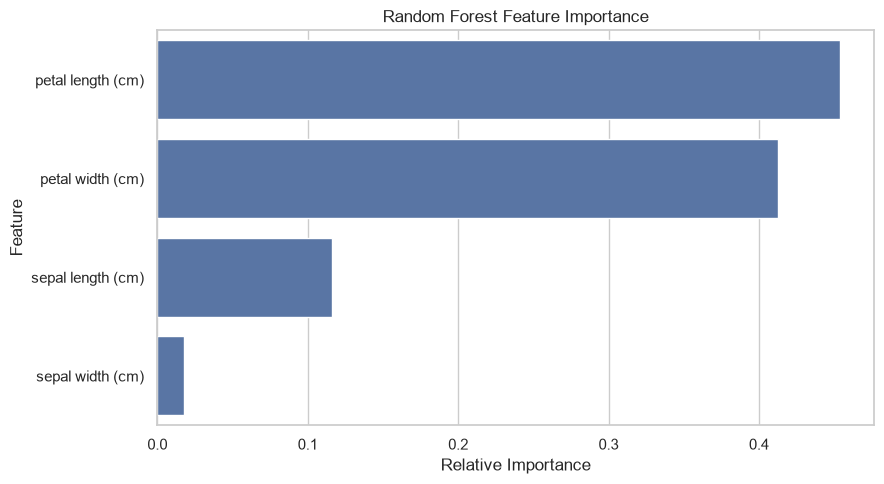

In [19]:
# Extract feature importance from the trained Random Forest model
rf_model = models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance values
display(feature_importance.round(4))

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Interpretation of Feature Importance

The feature-importance table and chart rank the four numerical measurements according to their contribution to the fitted Random Forest model.

Compare the ranking with the earlier pairplot and box plots. Features showing clearer differences between species may also receive higher importance scores, although the two analyses measure different things.

The ranking is specific to this fitted Random Forest model. It should not be interpreted as a causal relationship or as proof that a feature is universally the most important for every classifier.



## 14. Conclusion

This project applied supervised machine learning to classify iris flowers into Setosa, Versicolor, and Virginica using four numerical measurements: sepal length, sepal width, petal length, and petal width.

Exploratory data analysis was used to inspect the dataset, assess data quality, examine feature distributions, and visualize relationships between the measurements and species. The dataset contained 150 observations across three equally represented classes.

Three classification algorithms were trained and evaluated using an 80/20 stratified train/test split: Logistic Regression, K-Nearest Neighbors, and Random Forest. Their performance was assessed using accuracy, macro-averaged precision, recall, F1-score, and confusion matrices.

Logistic Regression and K-Nearest Neighbors both achieved 93.33% test accuracy, while Random Forest achieved 90.00%. Logistic Regression was selected as the preferred model because it combined the joint-highest accuracy with the highest macro F1-score among the evaluated models.

The analysis also examined Random Forest feature importance to better understand the relative contribution of the four measurements to that model's predictions.

### Limitations and Future Improvements

The evaluation used a single train/test split and a relatively small dataset. The reported results may vary with a different split or model configuration. Future work could include stratified cross-validation, systematic hyperparameter tuning, and a more detailed investigation of feature selection.

Overall, this project demonstrates a complete introductory machine learning workflow, from data inspection and visualization to model training, evaluation, comparison, and interpretation.
